In [1]:
!pip install roboflow

from google.colab import userdata
from roboflow import Roboflow

api_key = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=api_key)
project = rf.workspace("beyza-emul").project("helmet-detection-sfset")
version = project.version(1)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.6/324.6 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 53.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.9 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to helmet-detection-1 in yolov8:: 100%|██████████| 136/136 [00:00<00:00, 9393.27it/s]


In [2]:
!cat helmet-detection-1/data.yaml

names:
- helmet
- no_helmet
nc: 2
roboflow:
  license: Private
  project: helmet-detection-sfset
  url: https://app.roboflow.com/beyza-emul/helmet-detection-sfset/1
  version: 1
  workspace: beyza-emul
test: ../test/images
train: ../train/images
val: ../valid/images


In [3]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 43.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.0/91.0 kB 10.7 MB/s eta 0:00:00


In [5]:
!ls

helmet-detection-1  runs  sample_data  yolov8n.pt


In [6]:
!ls helmet-detection-1

data.yaml  README.roboflow.txt	train


In [7]:
import os, shutil, random

random.seed(0)
images_dir = "helmet-detection-1/train/images"
labels_dir = "helmet-detection-1/train/labels"

all_images = os.listdir(images_dir)
random.shuffle(all_images)
val_count = int(len(all_images) * 0.2)  # %20'sini valid'e ayır
val_images = all_images[:val_count]

os.makedirs("helmet-detection-1/valid/images", exist_ok=True)
os.makedirs("helmet-detection-1/valid/labels", exist_ok=True)

for img in val_images:
    label = img.rsplit(".", 1)[0] + ".txt"
    shutil.move(f"{images_dir}/{img}", f"helmet-detection-1/valid/images/{img}")
    if os.path.exists(f"{labels_dir}/{label}"):
        shutil.move(f"{labels_dir}/{label}", f"helmet-detection-1/valid/labels/{label}")

print(f"{val_count} görsel valid klasörüne taşındı.")

13 görsel valid klasörüne taşındı.


In [8]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.train(
    data="helmet-detection-1/data.yaml",
    epochs=50,
    imgsz=640,
    batch=8
)

Ultralytics 8.4.165 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=helmet-detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimiz


image 1/13 /content/helmet-detection-1/valid/images/pexels-anasjawed-16583980_jpg.rf.a1f347db605ff5916ffc41dd1e8531dc.jpg: 640x640 1 helmet, 1 no_helmet, 7.3ms
image 2/13 /content/helmet-detection-1/valid/images/pexels-bymuratisikofficial-34670929_jpg.rf.beb627da41bbdac0b1a2ffa16d97449c.jpg: 640x640 1 helmet, 2 no_helmets, 7.6ms
image 3/13 /content/helmet-detection-1/valid/images/pexels-cristian-rojas-8853471_jpg.rf.655ad292a52b8116bb18c15d68f479e3.jpg: 640x640 2 helmets, 9.7ms
image 4/13 /content/helmet-detection-1/valid/images/pexels-dauphotographer-35106289_jpg.rf.f39fd941b200e0024d4dc60d4b01fd9e.jpg: 640x640 1 no_helmet, 7.2ms
image 5/13 /content/helmet-detection-1/valid/images/pexels-filmy-kashif-2157365380-35175939_jpg.rf.b352aa680d42126aa0344b98530c4262.jpg: 640x640 2 no_helmets, 7.3ms
image 6/13 /content/helmet-detection-1/valid/images/pexels-kindelmedia-8487395_jpg.rf.4f0f63c8b458e1bc4a6042a3bf94d79f.jpg: 640x640 1 helmet, 7.3ms
image 7/13 /content/helmet-detection-1/valid/im

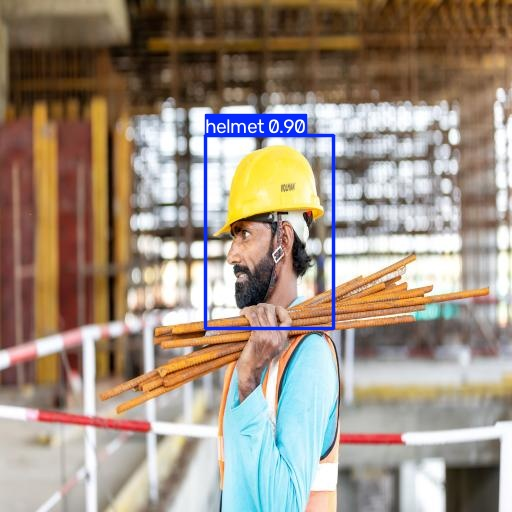

In [11]:
trained_model = YOLO("runs/detect/train-2/weights/best.pt")

results = trained_model("helmet-detection-1/valid/images", save=True)
import glob
from IPython.display import Image, display

latest = sorted(glob.glob("runs/detect/predict*/*.jpg"))[-1]
display(Image(latest))

In [15]:
import sqlite3
from datetime import datetime

conn = sqlite3.connect("detections.db")
cur = conn.cursor()

cur.execute("""
CREATE TABLE IF NOT EXISTS detections (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    image_name TEXT,
    detected_class TEXT,
    confidence REAL,
    timestamp TEXT
)
""")
conn.commit()
results = trained_model("helmet-detection-1/valid/images", save=False)

for r in results:
    image_name = r.path.split("/")[-1]
    for box in r.boxes:
        cls_name = trained_model.names[int(box.cls)]
        conf = float(box.conf)
        cur.execute(
            "INSERT INTO detections (image_name, detected_class, confidence, timestamp) VALUES (?, ?, ?, ?)",
            (image_name, cls_name, conf, datetime.now().isoformat())
        )

conn.commit()
print("Veritabanına yazıldı.")


image 1/13 /content/helmet-detection-1/valid/images/pexels-anasjawed-16583980_jpg.rf.a1f347db605ff5916ffc41dd1e8531dc.jpg: 640x640 1 helmet, 1 no_helmet, 13.9ms
image 2/13 /content/helmet-detection-1/valid/images/pexels-bymuratisikofficial-34670929_jpg.rf.beb627da41bbdac0b1a2ffa16d97449c.jpg: 640x640 1 helmet, 2 no_helmets, 7.3ms
image 3/13 /content/helmet-detection-1/valid/images/pexels-cristian-rojas-8853471_jpg.rf.655ad292a52b8116bb18c15d68f479e3.jpg: 640x640 2 helmets, 7.2ms
image 4/13 /content/helmet-detection-1/valid/images/pexels-dauphotographer-35106289_jpg.rf.f39fd941b200e0024d4dc60d4b01fd9e.jpg: 640x640 1 no_helmet, 7.7ms
image 5/13 /content/helmet-detection-1/valid/images/pexels-filmy-kashif-2157365380-35175939_jpg.rf.b352aa680d42126aa0344b98530c4262.jpg: 640x640 2 no_helmets, 7.2ms
image 6/13 /content/helmet-detection-1/valid/images/pexels-kindelmedia-8487395_jpg.rf.4f0f63c8b458e1bc4a6042a3bf94d79f.jpg: 640x640 1 helmet, 7.4ms
image 7/13 /content/helmet-detection-1/valid/i

In [16]:
# Kaç tespit var, sınıf bazında dağılım
query1 = """
SELECT detected_class, COUNT(*) as adet, ROUND(AVG(confidence), 3) as ort_guven
FROM detections
GROUP BY detected_class
"""
for row in cur.execute(query1):
    print(row)

('helmet', 8, 0.57)
('no_helmet', 17, 0.664)


In [17]:
# Güven skoru düşük (belirsiz) tespitler — modelin zorlandığı örnekler
query2 = """
SELECT image_name, detected_class, confidence
FROM detections
WHERE confidence < 0.5
ORDER BY confidence ASC
"""
for row in cur.execute(query2):
    print(row)

('pexels-mohsen-khodabakhshi-89808222-9078399_jpg.rf.dec1c2b28cc2537062a423480f1374d0.jpg', 'no_helmet', 0.28623032569885254)
('pexels-madknoxxdeluxe-36096170_jpg.rf.dcaf3baf69773f0f36ae27b1f4aa59a1.jpg', 'helmet', 0.2963506877422333)
('pexels-mohsen-khodabakhshi-89808222-9078399_jpg.rf.dec1c2b28cc2537062a423480f1374d0.jpg', 'no_helmet', 0.3222936987876892)
('pexels-filmy-kashif-2157365380-35175939_jpg.rf.b352aa680d42126aa0344b98530c4262.jpg', 'no_helmet', 0.37558963894844055)
('pexels-bymuratisikofficial-34670929_jpg.rf.beb627da41bbdac0b1a2ffa16d97449c.jpg', 'helmet', 0.39925912022590637)
('pexels-mohsen-khodabakhshi-89808222-9078399_jpg.rf.dec1c2b28cc2537062a423480f1374d0.jpg', 'helmet', 0.40176883339881897)
('pexels-kindelmedia-8487395_jpg.rf.4f0f63c8b458e1bc4a6042a3bf94d79f.jpg', 'helmet', 0.4581018090248108)
('pexels-anasjawed-16583980_jpg.rf.a1f347db605ff5916ffc41dd1e8531dc.jpg', 'no_helmet', 0.48447534441947937)
('pexels-pixel9inja-32620506_jpg.rf.4cbc80d85bbbe7c35d94bc204aedb22

In [18]:
# En çok tespit içeren görseller (kalabalık sahneler)
query3 = """
SELECT image_name, COUNT(*) as tespit_sayisi
FROM detections
GROUP BY image_name
ORDER BY tespit_sayisi DESC
LIMIT 5
"""
for row in cur.execute(query3):
    print(row)

('pexels-pixel9inja-32620506_jpg.rf.4cbc80d85bbbe7c35d94bc204aedb223.jpg', 3)
('pexels-mohsen-khodabakhshi-89808222-9078399_jpg.rf.dec1c2b28cc2537062a423480f1374d0.jpg', 3)
('pexels-bymuratisikofficial-34670929_jpg.rf.beb627da41bbdac0b1a2ffa16d97449c.jpg', 3)
('pexels-safari-consoler-3290243-11293626_jpg.rf.ba6a1541b598185a9ee0be7c247f17d3.jpg', 2)
('pexels-nishantaneja-9172008_jpg.rf.cbddca9a37962decceb1ed255228f1ee.jpg', 2)


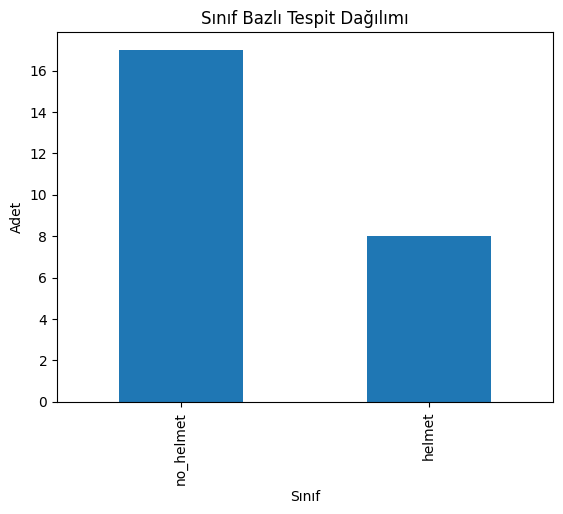

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_sql("SELECT * FROM detections", conn)

df["detected_class"].value_counts().plot(kind="bar", title="Sınıf Bazlı Tespit Dağılımı")
plt.xlabel("Sınıf")
plt.ylabel("Adet")
plt.savefig("class_distribution.png")
plt.show()

In [20]:
conn.close()